# Global PCA for Industrial Anomaly Detection

**CS 663 — Digital Image Processing | MVTec AD**

Each complete grayscale image is flattened into one feature vector. PCA learns the dominant appearance patterns from normal training images. New images are projected onto the learned subspace and reconstructed. Pixels with large squared reconstruction errors are treated as possible defects.

The model is fitted using defect-free training images only. Normal validation images are used to set the image-level threshold. The official test split and its masks are reserved for final evaluation.

The PCA calculations are implemented directly using NumPy matrix operations and eigenvalue decomposition. No prebuilt PCA estimator is used.

## 1. Setup and category selection

Set RUN_ALL_CATEGORIES to True to run the full 15-category benchmark. Leave it False for a quick smoke test on bottle. The dataset must be available under the configured MVTec root.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd
from scipy.ndimage import label as connected_components
from scipy.integrate import trapezoid
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    REPO = Path("/content/CS-663")
    if REPO.exists():
        subprocess.run(["git", "-C", str(REPO), "fetch", "origin", "global-pca-lecture-review-v2"], check=True)
        subprocess.run(["git", "-C", str(REPO), "checkout", "global-pca-lecture-review-v2"], check=True)
        subprocess.run(["git", "-C", str(REPO), "pull", "--ff-only", "origin", "global-pca-lecture-review-v2"], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", "global-pca-lecture-review-v2", "https://github.com/pranitas-cloud/CS-663.git", str(REPO)], check=True)
else:
    REPO = Path.cwd()
    if not (REPO / "src").is_dir():
        raise RuntimeError("Open this notebook from the CS-663 repository root.")

os.chdir(REPO)
if str(REPO.resolve()) not in sys.path:
    sys.path.insert(0, str(REPO.resolve()))

from src.data.pipelines import load_config, build_dataset, stack_images

CONFIG = load_config("configs/default.yaml")
DEFAULT_DATA_ROOT = Path("/content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection") if IN_COLAB else REPO / "data" / "mvtec_anomaly_detection"
DATA_ROOT = Path(os.environ.get("MVTEC_DATA_ROOT", DEFAULT_DATA_ROOT)).expanduser()
if not DATA_ROOT.is_absolute():
    DATA_ROOT = REPO / DATA_ROOT
CONFIG["data"]["root"] = str(DATA_ROOT)

SEED = int(CONFIG.get("seed", 42))
IMAGE_SIZE = int(CONFIG["pca"].get("image_size", 256))
EXPECTED_CATEGORIES = [
    "bottle", "cable", "capsule", "carpet", "grid",
    "hazelnut", "leather", "metal_nut", "pill", "screw",
    "tile", "toothbrush", "transistor", "wood", "zipper"
]
RUN_ALL_CATEGORIES = False
SMOKE_TEST_CATEGORY = "bottle"

np.random.seed(SEED)
torch.manual_seed(SEED)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"MVTec folder not found: {DATA_ROOT}")

available_categories = {
    folder.name for folder in DATA_ROOT.iterdir()
    if folder.is_dir() and (folder / "train" / "good").is_dir()
}

if RUN_ALL_CATEGORIES:
    missing_categories = sorted(set(EXPECTED_CATEGORIES) - available_categories)
    if missing_categories:
        raise FileNotFoundError(f"Missing MVTec categories: {missing_categories}")
    CATEGORIES_TO_RUN = EXPECTED_CATEGORIES
else:
    if SMOKE_TEST_CATEGORY not in available_categories:
        raise FileNotFoundError(f"Category not found: {SMOKE_TEST_CATEGORY}")
    CATEGORIES_TO_RUN = [SMOKE_TEST_CATEGORY]

print("Repository:", REPO)
print("Dataset:", DATA_ROOT)
print("Categories to run:", CATEGORIES_TO_RUN)
print("Run all 15 categories:", RUN_ALL_CATEGORIES)
print("Image size:", IMAGE_SIZE)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)

Mounted at /content/drive
Repository: /content/CS-663
Dataset: /content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection
Categories to run: ['bottle']
Run all 15 categories: False
Image size: 256
NumPy: 2.4.6
PyTorch: 2.14.1+cpu


## 2. PCA method

Let X contain one flattened normal training image per row. We subtract the mean calculated from the training images. The pixel-space covariance matrix is very large, so we eigendecompose the equivalent sample-space matrix G = Xc Xcᵀ. If u is an eigenvector with eigenvalue λ, the corresponding pixel-space principal direction is v = Xcᵀu / √λ. A new image is projected onto the retained directions and reconstructed.

The number of retained principal components is selected to explain the configured fraction of training variance. All mean and subspace calculations use the normal training data only.

In [2]:
from src.pca.global_pca import GlobalPCA

## 3. Synthetic sanity check

This small test checks output dimensions, finite non-negative anomaly scores and reconstruction behavior before the real dataset is processed.

In [3]:
random_generator = np.random.default_rng(SEED)
toy_images = random_generator.normal(size=(8, 1, 16, 16)).astype(np.float32)

toy_model = GlobalPCA(n_components="all", method="svd").fit(toy_images)
toy_reconstruction = toy_model.reconstruct(toy_images)
toy_anomaly_map = toy_model.anomaly_map(toy_images)

assert toy_reconstruction.shape == toy_images.shape
assert toy_anomaly_map.shape == (8, 16, 16)
assert np.isfinite(toy_anomaly_map).all()
assert toy_anomaly_map.min() >= 0
assert np.mean((toy_images - toy_reconstruction) ** 2) < 1e-8

print("Global PCA synthetic checks passed.")

Global PCA synthetic checks passed.


## 4. Evaluation protocol

For each category, the image threshold is set from the 95th percentile of normal validation image scores. It is fixed before evaluation on the official test split.

The notebook reports image AUROC, average precision, precision, recall and F1; pixel AUROC and average precision; and normalized AUPRO up to 30% pixel false-positive rate. Per-category metrics and their macro average are saved as CSV files.

In [4]:
def collect_outputs(dataset, model):
    image_labels = []
    image_scores = []
    masks = []
    anomaly_maps = []

    for index in range(len(dataset)):
        item = dataset[index]
        image = item["image"].unsqueeze(0).cpu().numpy()
        anomaly_map = model.anomaly_map(image)[0]
        mask = item["mask"].squeeze(0).cpu().numpy().astype(bool)

        image_labels.append(int(item["label"]))
        image_scores.append(float(anomaly_map.max()))
        masks.append(mask)
        anomaly_maps.append(anomaly_map)

    return (
        np.asarray(image_labels, dtype=np.uint8),
        np.asarray(image_scores, dtype=np.float64),
        np.stack(masks),
        np.stack(anomaly_maps)
    )


def compute_aupro(masks, anomaly_maps, max_fpr=0.30, number_of_thresholds=128):
    masks = np.asarray(masks, dtype=bool)
    anomaly_maps = np.asarray(anomaly_maps, dtype=np.float64)

    if masks.shape != anomaly_maps.shape:
        raise ValueError("Masks and anomaly maps must have identical shapes.")

    regions = []
    for mask in masks:
        region_labels, number_of_regions = connected_components(mask)
        for region_number in range(1, number_of_regions + 1):
            region = region_labels == region_number
            if region.any():
                regions.append(region)

    negative_pixels = int((~masks).sum())
    if not regions or negative_pixels == 0:
        return float("nan")

    thresholds = np.unique(
        np.quantile(anomaly_maps, np.linspace(0.0, 1.0, number_of_thresholds))
    )[::-1]

    false_positive_rates = [0.0]
    region_overlaps = [0.0]

    for threshold in thresholds:
        prediction = anomaly_maps >= threshold
        false_positive_rate = np.logical_and(prediction, ~masks).sum() / negative_pixels

        if false_positive_rate > max_fpr:
            break

        overlaps = [
            np.logical_and(prediction, region).sum() / region.sum()
            for region in regions
        ]

        false_positive_rates.append(float(false_positive_rate))
        region_overlaps.append(float(np.mean(overlaps)))

    x_values = np.asarray(false_positive_rates)
    y_values = np.asarray(region_overlaps)
    order = np.argsort(x_values)
    x_values = x_values[order]
    y_values = y_values[order]

    unique_x = np.unique(x_values)
    unique_y = np.asarray([y_values[x_values == value].max() for value in unique_x])

    inside = unique_x < max_fpr
    x_values = unique_x[inside]
    y_values = unique_y[inside]

    if len(x_values) == 0 or x_values[0] != 0.0:
        x_values = np.insert(x_values, 0, 0.0)
        y_values = np.insert(y_values, 0, 0.0)

    end_value = float(np.interp(max_fpr, unique_x, unique_y))
    x_values = np.append(x_values, max_fpr)
    y_values = np.append(y_values, end_value)

    return float(np.clip(trapezoid(y_values, x_values) / max_fpr, 0.0, 1.0))


def evaluate_model(model, validation_dataset, test_dataset, category_name, method_name):
    validation_labels, validation_scores, _, _ = collect_outputs(validation_dataset, model)
    if np.any(validation_labels != 0):
        raise ValueError("Validation data must contain normal images only.")

    image_threshold = float(np.quantile(validation_scores, 0.95, method="higher"))

    test_labels, test_scores, test_masks, test_maps = collect_outputs(test_dataset, model)
    if np.unique(test_labels).size != 2:
        raise ValueError(f"The test split for {category_name} must contain both classes.")

    image_predictions = (test_scores >= image_threshold).astype(np.uint8)
    flat_masks = test_masks.reshape(-1).astype(np.uint8)
    flat_scores = test_maps.reshape(-1)

    results = {
        "category": category_name,
        "method": method_name,
        "image_auroc": float(roc_auc_score(test_labels, test_scores)),
        "image_ap": float(average_precision_score(test_labels, test_scores)),
        "image_precision": float(precision_score(test_labels, image_predictions, zero_division=0)),
        "image_recall": float(recall_score(test_labels, image_predictions, zero_division=0)),
        "image_f1": float(f1_score(test_labels, image_predictions, zero_division=0)),
        "pixel_auroc": float(roc_auc_score(flat_masks, flat_scores)),
        "pixel_ap": float(average_precision_score(flat_masks, flat_scores)),
        "aupro_30pct_fpr": compute_aupro(test_masks, test_maps),
        "validation_threshold": image_threshold,
        "validation_images": len(validation_dataset),
        "test_images": len(test_dataset)
    }

    return pd.DataFrame([results]), test_maps, test_masks


def save_result_tables(category_results, method_name):
    results_table = pd.concat(category_results, ignore_index=True)
    metric_names = [
        "image_auroc", "image_ap", "image_precision", "image_recall",
        "image_f1", "pixel_auroc", "pixel_ap", "aupro_30pct_fpr"
    ]

    macro_values = results_table[metric_names].mean()
    macro_table = pd.DataFrame([{"method": method_name, "category": "MACRO", **macro_values.to_dict()}])

    output_directory = Path("results/tables")
    output_directory.mkdir(parents=True, exist_ok=True)

    category_path = output_directory / f"{method_name.lower().replace('-', '_').replace(' ', '_')}_categories.csv"
    macro_path = output_directory / f"{method_name.lower().replace('-', '_').replace(' ', '_')}_macro.csv"

    results_table.to_csv(category_path, index=False)
    macro_table.to_csv(macro_path, index=False)

    print("Category results saved to:", category_path)
    print("Macro results saved to:", macro_path)

    return results_table, macro_table

## 5. Run the selected categories

With RUN_ALL_CATEGORIES=False, this runs bottle only and provides a quick execution check. Set it to True in the setup cell to run all 15 categories. Each category's fitted model is saved separately.


Running Global PCA for: bottle
category  image_auroc  pixel_auroc  image_f1  runtime_seconds
  bottle        0.954       0.8683    0.9244         114.8212
Category results saved to: results/tables/global_pca_categories.csv
Macro results saved to: results/tables/global_pca_macro.csv


,category,method,image_auroc,image_ap,image_precision,image_recall,image_f1,pixel_auroc,pixel_ap,aupro_30pct_fpr,validation_threshold,validation_images,test_images,runtime_seconds,training_images,components,retained_variance
0,bottle,Global PCA,0.954,0.9871,0.9821,0.873,0.9244,0.8683,0.4057,1.0,0.2504,21,83,114.8212,188,104,0.9504


,method,category,image_auroc,image_ap,image_precision,image_recall,image_f1,pixel_auroc,pixel_ap,aupro_30pct_fpr
0,Global PCA,MACRO,0.954,0.9871,0.9821,0.873,0.9244,0.8683,0.4057,1.0


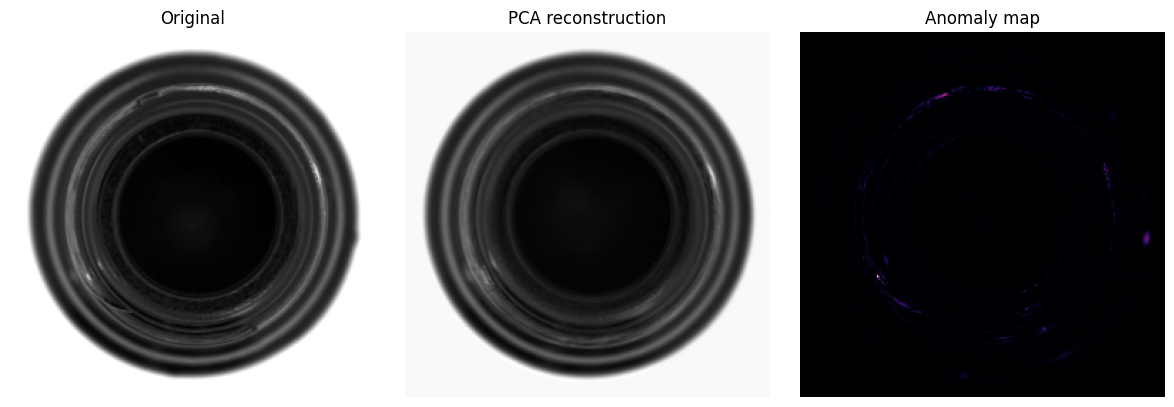

In [5]:
RETAINED_VARIANCE = 0.95

category_results = []
first_preview = None

for category_name in CATEGORIES_TO_RUN:
    print("\nRunning Global PCA for:", category_name)
    start_time = time.perf_counter()

    train_dataset = build_dataset(CONFIG, "pca", "train", category_name)
    validation_dataset = build_dataset(CONFIG, "pca", "val", category_name)
    test_dataset = build_dataset(CONFIG, "pca", "test", category_name)

    training_images = stack_images(train_dataset).cpu().numpy()

    assert all(sample[2] == "good" for sample in train_dataset.samples)
    assert all(sample[2] == "good" for sample in validation_dataset.samples)

    model = GlobalPCA(n_components=RETAINED_VARIANCE, method="svd", ddof=0)
    model.fit(training_images)

    metrics, test_maps, test_masks = evaluate_model(
        model,
        validation_dataset,
        test_dataset,
        category_name,
        "Global PCA"
    )

    elapsed_seconds = time.perf_counter() - start_time
    metrics["runtime_seconds"] = elapsed_seconds
    metrics["training_images"] = len(train_dataset)
    metrics["validation_images"] = len(validation_dataset)
    metrics["test_images"] = len(test_dataset)
    metrics["components"] = model.n_components_
    metrics["retained_variance"] = float(model.explained_variance_ratio_.sum())


    model_directory = Path("experiments/pca") / "global"
    model_directory.mkdir(parents=True, exist_ok=True)
    model.save(model_directory / f"{category_name}.npz")

    category_results.append(metrics)
    print(metrics[["category", "image_auroc", "pixel_auroc", "image_f1", "runtime_seconds"]].round(4).to_string(index=False))

    if first_preview is None:
        example = validation_dataset[0]
        example_image = example["image"].unsqueeze(0).cpu().numpy()
        first_preview = (
            example_image[0, 0],
            model.reconstruct(example_image)[0, 0],
            model.anomaly_map(example_image)[0]
        )

category_table, macro_table = save_result_tables(category_results, "Global PCA")
display(category_table.round(4))
display(macro_table.round(4))

if first_preview is not None:
    original_image, reconstructed_image, error_map = first_preview
    figure, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(original_image, cmap="gray")
    axes[0].set_title("Original")
    axes[1].imshow(reconstructed_image, cmap="gray")
    axes[1].set_title("PCA reconstruction")
    axes[2].imshow(error_map, cmap="inferno")
    axes[2].set_title("Anomaly map")
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

## 6. Interpretation and limitations



The image-level threshold is calibrated on normal validation images. Test labels and masks are used only for final metrics. A one-category smoke test is not a dataset-wide result; use the all-category mode before reporting macro performance.